# 06 · Checking the test labels by hand

**The question this step answers:** can we trust the answer key of the final exam? Rule-based accounts are right by construction: the generator picked the group itself. LLM-written accounts carry the group *the LLM says* it meant, and the LLM can be wrong. So before the test pile is used, a person checks:
- **every** LLM-written test account (200);
- a random **50** of the 400 rule-based ones, because heavy noise can make a name truly ambiguous.

**Where it sits in the pipeline:** after the piles are built (notebook 05) and before anything is evaluated on test. The evaluation reads only the result, `data/generated/test_checked.jsonl`.

**The code:** `src/d1/datagen/handcheck.py`: `export_review` → you fill in the CSV in Excel → `apply_review`. Commands: `python -m d1.datagen export-review` and `apply-review`.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

from d1.datagen.schema import read_jsonl

review = pd.read_csv(config.data.review_path, sep=";", encoding="utf-8-sig", dtype=str, keep_default_na=False)
review["verdict"] = review["verdict"].str.strip().str.lower()
checked = read_jsonl(config.data.generated_dir / "test_checked.jsonl")
print(f"{len(review)} rows checked by hand; {len(checked)} test accounts after applying the verdicts")

250 rows checked by hand; 598 test accounts after applying the verdicts


## 1. One row, as you saw it

Each row of `data/labels/test_review.csv` shows the account as the company wrote it, the group it is labelled with, and that group's names. You filled in **verdict**: `ok` (right group), `fix` (put the right group in `corrected_target`) or `drop` (no group fits). One of the fixes:

In [2]:
example = review[review["verdict"] == "fix"].iloc[0]
display(example.to_frame(name=example["account_id"]))
print(f"labelled: {example['target_code']} {by_code[example['target_code']].name_en}\ncorrected: {example['corrected_target']} {by_code[example['corrected_target']].name_en}")

,test-c008-024
account_id,test-c008-024
company_id,test-c008
industry,software
language,en
source,llm
code,7921
name,Transfer from untaxed reserves
target_code,792
target_name_en,Withdrawals From Reserves
target_name_local,Withdrawals From Reserves


labelled: 792 Withdrawals From Reserves
corrected: 789 Transfer From Untaxed Reserves


## 2. What happens, step by step

1. **`export-review`** picks the rows (all LLM-written, plus a seeded random 50 rule-based) and writes them as a CSV that Excel opens correctly in a Belgian setup (`;` separator, accents intact). It refuses to overwrite a file that already has verdicts, so hand work can never be lost.
2. **You fill in a verdict for every row.**
3. **`apply-review`** reads the file back and **checks every row first**: a known account, not listed twice, the name unchanged since the export, a valid verdict, a real group for every fix. If anything is wrong, it lists *all* problems at once and applies nothing.
4. **The verdicts are applied** to the whole test pile and written to `test_checked.jsonl`:
   - `ok` → kept, marked *checked*;
   - `fix` → the group is replaced, marked *corrected*;
   - `drop` → removed;
   - rule-based rows that weren't sampled are kept, marked *constructed*.

In [3]:
status = pd.Series(Counter(r.label_status for r in checked)).reindex(["checked", "corrected", "constructed"])
display(status.rename("test accounts").to_frame())

,test accounts
checked,224
corrected,24
constructed,350


## 3. The result

How many rows got each verdict:

In [4]:
display(pd.crosstab(review["source"], review["verdict"], margins=True, margins_name="total")[["ok", "fix", "drop", "total"]])

verdict,ok,fix,drop,total
source,,,,
llm,174,24,2,200
rules,50,0,0,50
total,224,24,2,250


- **Rule-based: 50 of 50 OK.** "Right by construction" holds on the sample.
- **LLM-written: 26 of 200 (13%) needed a fix or a drop.** That's why checking them mattered. Without the check, the final exam would mark a correct mapper wrong on about one LLM account in eight.

By language, for the LLM-written rows:

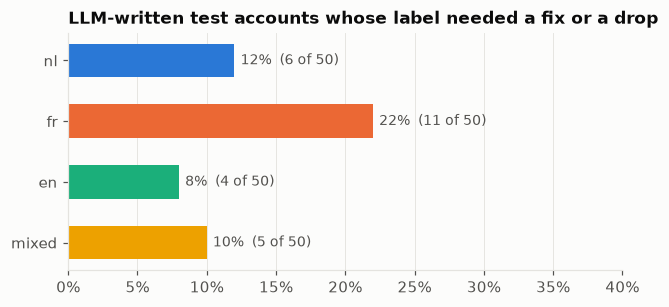

In [5]:
llm = review[review["source"] == "llm"]
wrong = llm.assign(wrong=llm["verdict"] != "ok").groupby("language")["wrong"].agg(["mean", "sum", "size"]).reindex(["nl", "fr", "en", "mixed"])
fig, ax = plt.subplots(figsize=(6.5, 2.8))
bars = ax.barh(wrong.index, wrong["mean"], color=[LANGUAGE_COLORS[l] for l in wrong.index], height=0.55)
ax.bar_label(bars, labels=[f"{m:.0%}  ({s} of {n})" for m, s, n in zip(wrong["mean"], wrong["sum"], wrong["size"])], padding=4, fontsize=9, color=INK_2)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct())
ax.set_xlim(0, 0.4)
ax.grid(axis="y", visible=False)
ax.set_title("LLM-written test accounts whose label needed a fix or a drop")
plt.show()

## 4. Every fix

The 24 corrected labels. Most are near misses within the same class: the LLM picked a group next to the right one. For example, advance invoices sent to a customer belong with *Customers* (400), not *Advance Payments* (406), and a rent deposit paid is a *Cash Guarantee Paid* (288), not an *Other Amount Receivable* (291).

In [6]:
fixes = review[review["verdict"] == "fix"].copy()
fixes["LLM's label"] = fixes["target_code"].map(lambda c: f"{c} {by_code[c].name_en}")
fixes["corrected to"] = fixes["corrected_target"].map(lambda c: f"{c} {by_code[c].name_en}")
fixes["same class"] = fixes["target_code"].str[0] == fixes["corrected_target"].str[0]
display(fixes[["name", "language", "LLM's label", "corrected to", "same class"]].reset_index(drop=True))
print(f"same class: {fixes['same class'].sum()} of {len(fixes)}")

,name,language,LLM's label,corrected to,same class
0,Transfer from untaxed reserves,en,792 Withdrawals From Reserves,789 Transfer From Untaxed Reserves,True
1,Waarborg ontvangen onderaannemers,mixed,428 Guarantees Received in Cash (> 1 Year Falling Due < 1 Year),488 Guarantees Received in Cash,True
2,Caution reçue locataire dépôt,mixed,428 Guarantees Received in Cash (> 1 Year Falling Due < 1 Year),488 Guarantees Received in Cash,True
3,Variation en-cours chantiers,mixed,712 Increase (Decrease) in Stocks of Work in Progress,717 Increase (Decrease) in Contracts in Progress,True
4,Verpakkingsmat. voorraad (dozen/zakken),nl,300 Raw Materials - Acquisition Value,310 Consumables - Acquisition Value,True
5,Straight loan rek.-crt.,nl,433 Credit Institutions - Current Account Payable,430 Credit Institutions - Fixed Term Loans,True
6,Meerwaarde verkoop rek & inrichting,nl,764 Other Non-Recurring Operating Income,741 Capital Profits on Ordinary Disposal of Tangible Fixed Assets,True
7,Garantie locative LT bureaux,fr,291 Other Amounts Receivable (> 1 Year),288 Cash Guarantees Paid,True
8,Prêt gérant (compte courant LT),fr,439 Other Loans,174 Other Loans (> 1 Year),False
9,Pécule vacances à payer,fr,455 Remuneration,456 Holiday Pay,True


same class: 21 of 24


## 5. The two drops

Accounts that fit no group of the standard chart at all, with your notes:

In [7]:
display(review[review["verdict"] == "drop"][["name", "language", "target_code", "note"]].reset_index(drop=True))

,name,language,target_code,note
0,Office supplies & consumables,en,601,"Office supplies are services & sundry goods (61), and the standard chart has no 3-digi..."
1,Terugname prov. geschil bouwheer,mixed,762,Correct group 638 is missing from the Odoo chart. A dispute provision with a client is...


One of them shows a gap in the target list itself. A reversal of a provision for a client dispute belongs in group 638, but Odoo's groups for class 63 stop at 637 (notebook 01). No mapping method can ever predict 638, which is a limitation worth stating.

## 6. What is *not* happening

- **Train and dev are not checked.** Checking 5,000 LLM-written rows by hand isn't realistic. They keep the LLM's labels, so every method's score on LLM-written *dev* accounts is a little pessimistic. That affects all methods alike, so comparisons on dev still hold.
- **The test file is not tuned on.** `test_checked.jsonl` is read once per reported run, and every such run is logged (Task 2.5).